# Phase 3 · Model 4 — Robot anomaly (fault) detection

**Goal:** from a short window of a robot's telemetry, decide whether it is behaving abnormally.

**Data:** `data/processed/classical_ml/anomaly_windows.parquet` — 5.2 million 20-tick windows with the
true fault label.

Workflow: 1 Understand → 2 Explore → 3 Target + features → 4 Split → 5 Preprocess → 6 Baseline →
7 Train → 8 Validate & tune → 9 Test once → 10 Save & report.

## Step 1 — Understand the problem

| Question | Answer |
|---|---|
| What do we predict? | `is_anomaly` (1 = a fault is active), and which `fault_type` we catch |
| When? | At the end of each 20-tick window, from that window's telemetry |
| Problem type | **Unsupervised anomaly detection** and **supervised classification** |
| How do we judge it? | **Precision, recall, F1** overall and **recall per fault type** |

Two families are compared, as the project map asks:

- **Unsupervised** (no labels — like a real site where nobody has labelled faults):
  **Isolation Forest** and **DBSCAN**.
- **Supervised** (learns from the labels): **Gradient Boosting** and **XGBoost**.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Find the project root (the folder that contains data/processed), wherever the notebook runs.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
DATA = ROOT / "data" / "processed" / "classical_ml"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 60)
print("Data folder:", DATA)

Data folder: H:\ai-warehouse-platform\data\processed\classical_ml


## Step 2 — Explore the data

5.2 million rows is large for a laptop, so we read only the needed columns and work with random samples
(500,000 for training). Samples are big enough to learn from and keep memory and time low.

In [2]:
FEATURES = [
    "move_rate", "move_rate_when_busy", "stop_count", "battery_delta", "battery_min_step",
    "temperature_mean", "temperature_max", "temperature_delta", "blocked_max",
    "route_len_mean", "route_len_growth", "task_elapsed_max", "congestion_mean",
]  # fmt: skip
df = pd.read_parquet(DATA / "anomaly_windows.parquet", columns=FEATURES + ["is_anomaly", "fault_type", "split"])
print("Rows:", f"{len(df):,}")
print(df["fault_type"].value_counts(normalize=True).round(4))

Rows: 5,237,960


fault_type
none                 0.8637
overheating          0.0569
speed_degradation    0.0330
stop_event           0.0189
route_deviation      0.0181
battery_spike        0.0094
Name: proportion, dtype: float64


How each fault type looks in the features: the signals a model can use.

In [3]:
cols = ["move_rate_when_busy", "stop_count", "battery_min_step", "temperature_max", "route_len_growth"]
df.groupby("fault_type")[cols].mean().round(2)

,move_rate_when_busy,stop_count,battery_min_step,temperature_max,route_len_growth
fault_type,,,,,
battery_spike,0.74,0.40,-13.38,34.62,11.25
none,0.53,0.39,-0.04,34.16,8.80
overheating,0.48,0.40,-0.05,56.52,8.10
route_deviation,0.56,0.34,-0.08,34.44,9.58
speed_degradation,0.35,0.34,-0.04,33.00,5.96
stop_event,0.18,3.89,-0.07,32.93,2.83


## Step 3 — Choose the target and the features

- **Target:** `is_anomaly` (also reported by `fault_type`).
- **Features:** the 13 window statistics above (movement, stops, battery, temperature, blocking,
  route, task time, congestion).
- **Excluded:** `robot_id`, `run_id`, ticks (identifiers) and `fault_type` (the answer).

## Step 4 — Split

By date (`split` column), then sampled: 500k train, 200k validation; the full test split is used at the end.

In [4]:
train = df[df["split"] == "train"].sample(500_000, random_state=42)
val = df[df["split"] == "validation"].sample(200_000, random_state=42)
test = df[df["split"] == "test"]
del df  # free memory
X_train, y_train = train[FEATURES], train["is_anomaly"]
X_val, y_val = val[FEATURES], val["is_anomaly"]
X_test, y_test = test[FEATURES], test["is_anomaly"]
for name, y in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:10s} {len(y):9,} windows, anomaly share {y.mean():.3f}")

train        500,000 windows, anomaly share 0.132
validation   200,000 windows, anomaly share 0.146
test         805,840 windows, anomaly share 0.148


## Step 5 — Preprocess

All features are numeric. The unsupervised methods measure distances, so features are **scaled**
with statistics of **normal** training windows only (what "normal" looks like). Trees need no scaling.

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train[y_train == 0])

## Step 6 — Baselines

1. "Never an anomaly" — zero recall.
2. A hand-written rule an engineer might use: hot motor, big battery drop, or barely moving while it has
   a route. A model must beat this.

In [6]:
from sklearn.metrics import f1_score, precision_score, recall_score


def scores(y_true, pred):
    return {
        "precision": round(precision_score(y_true, pred, zero_division=0), 3),
        "recall": round(recall_score(y_true, pred), 3),
        "F1": round(f1_score(y_true, pred), 3),
    }


def rule(X):
    hot = X["temperature_max"] > 55
    drop = X["battery_min_step"] < -5
    slow = (X["move_rate_when_busy"] < 0.4) & (X["route_len_mean"] > 0)
    return (hot | drop | slow).astype(int)


results = {
    "Baseline: never": scores(y_val, np.zeros(len(y_val), dtype=int)),
    "Baseline: hand rule": scores(y_val, rule(X_val)),
}
pd.DataFrame(results).T

,precision,recall,F1
Baseline: never,0.000,0.000,0.0
Baseline: hand rule,0.654,0.404,0.5


## Step 7a — Unsupervised: Isolation Forest

Trained only on **normal** windows; it learns what normal looks like and gives every window an
"abnormality" score (windows that are easy to isolate with random splits score high).

In [7]:
import time

from sklearn.ensemble import IsolationForest
from sklearn.pipeline import make_pipeline

start = time.time()
iso = make_pipeline(StandardScaler(), IsolationForest(n_estimators=200, random_state=42, n_jobs=-1))
iso.fit(X_train[y_train == 0])
iso_score_val = -iso.score_samples(X_val)  # higher = more abnormal
print(f"Isolation Forest trained in {time.time() - start:.1f} s")

Isolation Forest trained in 6.2 s


## Step 7b — Unsupervised: DBSCAN

DBSCAN groups windows that lie close together (dense regions = normal behaviour) and labels windows
that belong to **no group** as noise (`-1`) — those are the anomalies. Two settings: `eps` (how close
counts as "together") and `min_samples` (how many neighbours make a dense region).

DBSCAN compares every point with its neighbours, so it does not scale to millions of rows. We run it on
30,000-window samples, and collapse identical windows (thousands of parked robots look exactly the
same) into one point with a **weight** — the same result with far less memory. DBSCAN cannot score new
windows without re-clustering, so it is an **offline analysis** tool, not a live model.

In [8]:
from sklearn.cluster import DBSCAN


def dbscan_flags(X, eps, min_samples=50):
    z = np.round(scaler.transform(X), 1)  # 0.1 standard deviations is "the same window"
    unique, inverse, counts = np.unique(z, axis=0, return_inverse=True, return_counts=True)
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit(unique, sample_weight=counts).labels_
    return (labels[inverse.ravel()] == -1).astype(int)


val_sample = val.sample(30_000, random_state=1)
dbscan_tuning = []
for eps in (1.0, 1.25, 1.5, 1.75, 2.0):
    start = time.time()
    flags = dbscan_flags(val_sample[FEATURES], eps)
    dbscan_tuning.append({"eps": eps, **scores(val_sample["is_anomaly"], flags),
                          "flagged": round(flags.mean(), 3), "seconds": round(time.time() - start, 1)})  # fmt: skip
dbscan_tuning = pd.DataFrame(dbscan_tuning)
best_eps = float(dbscan_tuning.loc[dbscan_tuning["F1"].idxmax(), "eps"])
print("Best eps on validation:", best_eps)
dbscan_tuning

Best eps on validation: 1.5


,eps,precision,recall,F1,flagged,seconds
0,1.00,0.293,0.681,0.410,0.343,9.6
1,1.25,0.429,0.583,0.495,0.201,10.6
2,1.50,0.615,0.487,0.544,0.117,10.9
3,1.75,0.733,0.425,0.538,0.086,28.8
4,2.00,0.764,0.277,0.406,0.054,30.4


## Step 7c — Supervised: Gradient Boosting and XGBoost

Both learn from the labels, weighted so the rare faults count as much as normal windows.

In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()
supervised = {
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=ratio, tree_method="hist", n_jobs=-1, random_state=42,
    ),
}  # fmt: skip
proba_val = {}
for name, model in supervised.items():
    start = time.time()
    model.fit(X_train, y_train)
    proba_val[name] = model.predict_proba(X_val)[:, 1]
    print(f"{name:18s} trained in {time.time() - start:5.1f} s")

Gradient Boosting  trained in  13.1 s


XGBoost            trained in  38.8 s


## Step 8 — Validate & tune

Every scoring model gets its **threshold** chosen on validation to maximise F1 (for Isolation Forest
this is the only place labels are used). DBSCAN's `eps` was tuned in step 7b.

In [10]:
def best_threshold(score, y):
    grid = np.quantile(score, np.linspace(0.5, 0.995, 60))
    f1s = [f1_score(y, (score >= t).astype(int)) for t in grid]
    return float(grid[int(np.argmax(f1s))])


thresholds = {"Isolation Forest": best_threshold(iso_score_val, y_val)}
results["Isolation Forest"] = scores(y_val, (iso_score_val >= thresholds["Isolation Forest"]).astype(int))
for name in supervised:
    thresholds[name] = best_threshold(proba_val[name], y_val)
    results[name] = scores(y_val, (proba_val[name] >= thresholds[name]).astype(int))
best_name = max(supervised, key=lambda n: results[n]["F1"])
print("Best supervised model on validation:", best_name)
pd.DataFrame(results).T

Best supervised model on validation: XGBoost


,precision,recall,F1
Baseline: never,0.000,0.000,0.000
Baseline: hand rule,0.654,0.404,0.500
Isolation Forest,0.413,0.560,0.476
Gradient Boosting,0.956,0.692,0.803
XGBoost,0.959,0.694,0.806


## Step 9 — Test once

**A. Full test split** (last 2 weeks): the rule, Isolation Forest and both supervised models.
**B. Unsupervised comparison** on a 30,000-window test sample, where DBSCAN can run too.
**C. Recall per fault type** — which faults each method catches.

In [11]:
def flags_for(name, X):
    if name == "Hand rule":
        return rule(X)
    if name == "Isolation Forest":
        return (-iso.score_samples(X) >= thresholds[name]).astype(int)
    return (supervised[name].predict_proba(X)[:, 1] >= thresholds[name]).astype(int)


methods = ["Hand rule", "Isolation Forest", *supervised]
test_flags = {m: flags_for(m, X_test) for m in methods}
test_scores = {m: scores(y_test, f) for m, f in test_flags.items()}
print("A. Full test split")
display(pd.DataFrame(test_scores).T)

sample = test.sample(30_000, random_state=2)
unsupervised = {
    "Isolation Forest": scores(sample["is_anomaly"], flags_for("Isolation Forest", sample[FEATURES])),
    "DBSCAN": scores(sample["is_anomaly"], dbscan_flags(sample[FEATURES], best_eps)),
    best_name: scores(sample["is_anomaly"], flags_for(best_name, sample[FEATURES])),
}
print("B. 30,000-window test sample: unsupervised vs supervised")
display(pd.DataFrame(unsupervised).T)

per_type = pd.DataFrame(
    {m: pd.Series(f, index=test.index).groupby(test["fault_type"]).mean() for m, f in test_flags.items()}
).round(3)
print("C. Share of windows flagged, per fault type ('none' = false-alarm rate)")
display(per_type)

A. Full test split


,precision,recall,F1
Hand rule,0.655,0.412,0.506
Isolation Forest,0.416,0.575,0.483
Gradient Boosting,0.954,0.704,0.810
XGBoost,0.956,0.707,0.813


B. 30,000-window test sample: unsupervised vs supervised


,precision,recall,F1
Isolation Forest,0.418,0.569,0.482
DBSCAN,0.599,0.486,0.537
XGBoost,0.954,0.707,0.812


C. Share of windows flagged, per fault type ('none' = false-alarm rate)


,Hand rule,Isolation Forest,Gradient Boosting,XGBoost
fault_type,,,,
battery_spike,0.654,0.181,0.657,0.685
none,0.038,0.140,0.006,0.006
overheating,0.690,0.856,0.977,0.977
route_deviation,0.021,0.128,0.079,0.080
speed_degradation,0.045,0.423,0.616,0.618
stop_event,0.425,0.581,0.619,0.622


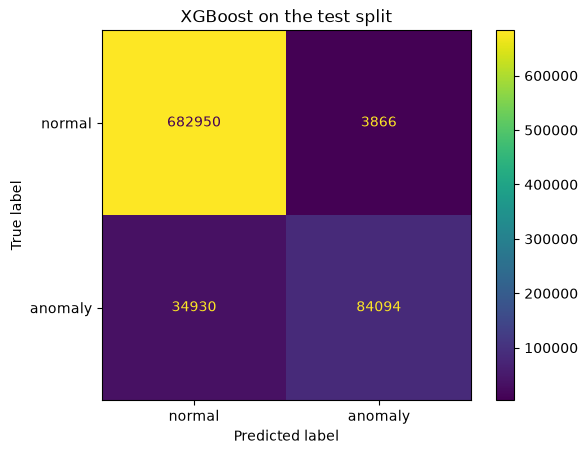

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, test_flags[best_name], display_labels=["normal", "anomaly"])
plt.title(f"{best_name} on the test split")
plt.show()

## Step 10 — Save & report

The best supervised model is saved for live use (the backend scores every robot every 10 ticks);
Isolation Forest is saved as the label-free alternative. DBSCAN is reported but not saved (it cannot
score new windows without re-clustering).

In [13]:
bundle = {"model": supervised[best_name], "threshold": thresholds[best_name],
          "features": FEATURES, "algorithm": best_name}  # fmt: skip
joblib.dump(bundle, MODELS / "anomaly_v1.joblib")
joblib.dump({"model": iso, "threshold": thresholds["Isolation Forest"], "features": FEATURES},
            MODELS / "anomaly_iforest_v1.joblib")  # fmt: skip
report = {
    "model": "anomaly_v1",
    "algorithm": best_name,
    "features": FEATURES,
    "dataset_version": "v3",
    "thresholds": thresholds,
    "dbscan": {"eps": best_eps, "min_samples": 50, "tuning": dbscan_tuning.to_dict("records")},
    "validation": results,
    "test": test_scores,
    "test_unsupervised_sample": unsupervised,
    "recall_per_fault_type": per_type.to_dict(),
}
(MODELS / "anomaly_v1_report.json").write_text(json.dumps(report, indent=2))
print("Saved models/anomaly_v1.joblib and models/anomaly_iforest_v1.joblib")

Saved models/anomaly_v1.joblib and models/anomaly_iforest_v1.joblib


## Summary

**What we predict:** whether a robot is behaving abnormally (a fault is active) from a 20-tick window
of its telemetry — and which kinds of fault are caught.

**Before (without this model):** faults were noticed when a robot visibly stopped, or with a fixed
hand-written rule, which reaches only F1 **0.51**.

**A. Full test split (last 2 weeks)**

| Method | Precision | Recall | F1 |
|---|---|---|---|
| Hand rule | 0.655 | 0.412 | 0.506 |
| Isolation Forest | 0.416 | 0.575 | 0.483 |
| Gradient Boosting | 0.954 | 0.704 | 0.81 |
| XGBoost | 0.956 | 0.707 | 0.813 |

**B. Unsupervised methods on a 30,000-window test sample** (DBSCAN cannot run on millions of rows;
best `eps` = 1.5 chosen on validation)

| Method | Precision | Recall | F1 |
|---|---|---|---|
| Isolation Forest | 0.418 | 0.569 | 0.482 |
| DBSCAN | 0.599 | 0.486 | 0.537 |
| XGBoost | 0.954 | 0.707 | 0.812 |

**C. Share of fault windows caught by XGBoost, per fault type**

| overheating | battery spike | speed degradation | stop event | route deviation | false alarms (normal) |
|---|---|---|---|---|---|
| 98% | 68% | 62% | 62% | 8% | 0.6% |

**What it shows**
- **Supervised beats unsupervised by a wide margin**: labels tell the model what a fault looks like.
  Gradient Boosting and XGBoost are close; XGBoost was best on validation.
- **Without labels**, DBSCAN (density: windows far from any dense group of normal behaviour) and
  Isolation Forest (how easily a window can be isolated) both find faults, but with many false alarms —
  heavy traffic also looks "unusual". On a real site without labelled faults, they are the starting point.
- Faults with a clear signal are caught well (overheating via temperature); route deviation looks like
  normal traffic in a short window and needs better features or sequence models (Phase 5).

**How it is used:** the backend scores every robot every 10 ticks; a robot turning abnormal raises an
`ANOMALY` alert, shows in the Fleet table and is saved with the true fault state.

**Saved:** `models/anomaly_v1.joblib` (XGBoost + threshold), `models/anomaly_iforest_v1.joblib`,
`models/anomaly_v1_report.json` (DBSCAN results included; DBSCAN itself cannot score new windows).